# 09. Evaluation on 2015 and the decision policy

**The question this notebook answers:** on loans the model never saw and that played no part in choosing it, how well does it rank and price risk, is it better than the platform's own grade, and which PD thresholds should the credit team use to approve, review or decline?

**What the brief asks:**
1. Report **ROC-AUC, Gini, KS**, a **calibration plot** and **performance by quarter** on the **2015 validation loans**, and **compare against using grade alone**.
2. Propose **auto-approve and auto-decline PD thresholds**, assuming a defaulted loan **loses 70%** of `loan_amnt` and a repaid loan **earns 10%** of it, and show the resulting **approval and default rates**.
3. **Compare outcomes across `addr_state` regions and income bands.**

The same analysis runs as `scripts/b1_evaluate_model.py`, which writes every table and chart to `reports/b1_model_evaluation/`. Here the main numbers are recomputed from the saved models; the bootstrap intervals (thousands of resamples) are read from that script's tables.

**Terms used in this notebook**
- **AUC:** the chance that a randomly picked defaulted loan gets a higher PD than a randomly picked repaid loan (0.5 is guessing).
- **Gini:** `2 x AUC - 1`, the same ranking measure on a 0-to-1 scale that credit teams often quote.
- **KS (Kolmogorov-Smirnov):** the largest gap, at any PD cut-off, between the share of defaulted loans and the share of repaid loans below it. Larger means the model separates the two groups better somewhere along the scale.
- **Brier score:** the average squared gap between PD and outcome; lower is better.
- **Calibration slope:** fit `observed = a + b x predicted` on the log-odds scale; a slope of 1 means high PDs are as high as they should be and low PDs as low.
- **Bootstrap interval:** resample the same 2015 loans with replacement many times and recompute the difference; the middle 95% of those differences is the interval. If it excludes zero, the difference is unlikely to be chance.
- **Grade alone:** the platform's sub-grade (A1 to G5) turned into a PD with the same per-term calibration as our models. It is the old system we must beat.

In [1]:
import os, json, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk.model import metrics, policy
from credit_risk.model.data import load_config, split, training_frames
from credit_risk.model.models import add_grade_rank

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

cfg = load_config("config/train.yaml")
TAB = Path("reports/b1_model_evaluation/tables")
_, _, frame = training_frames(cfg)
frame = add_grade_rank(frame)
NAMES = {"grade_baseline": "grade alone", "woe_scorecard": "scorecard, no platform score", "lightgbm": "boosting, no platform score",
         "scorecard_plus_grade": "scorecard + sub-grade", "lightgbm_plus_grade": "boosting + sub-grade", "scorecard_boosted_average": "selected: average of the two"}
bundles = {n: joblib.load(f"models/{n}.joblib") for n in NAMES}
v15 = split(frame, "2015-01-01", "2015-12-31").copy()
for n, b in bundles.items():
    v15[n] = b.score(v15)
v15["quarter"] = v15.issue_d.dt.to_period("Q").astype(str)
SEL = "scorecard_boosted_average"
print(f"2015 loans: {len(v15):,}; default rate {v15.defaulted.mean():.1%}; every model scores them with the transform and models saved at training")

2015 loans: 15,627; default rate 20.1%; every model scores them with the transform and models saved at training


## 1. Ranking on 2015: AUC, Gini, KS and Brier

In [2]:
rows = [{"model": NAMES[n], **metrics.summary(v15.defaulted, v15[n])} for n in NAMES]
res = pd.DataFrame(rows).set_index("model")[["auc", "gini", "ks", "brier", "mean_pd", "default_rate"]]
print(res.round(4).to_string())
print(f"\nfor reference, the raw sub-grade rank with no calibration at all: AUC {metrics.auc(v15.defaulted, v15.sub_grade_rank):.4f}")

                                 auc    gini      ks   brier  mean_pd  default_rate
model                                                                              
grade alone                   0.7218  0.4437  0.3222  0.1450   0.1755        0.2009
scorecard, no platform score  0.7183  0.4366  0.3217  0.1439   0.1868        0.2009
boosting, no platform score   0.7246  0.4492  0.3350  0.1429   0.1890        0.2009
scorecard + sub-grade         0.7339  0.4679  0.3424  0.1420   0.1840        0.2009
boosting + sub-grade          0.7345  0.4690  0.3428  0.1419   0.1840        0.2009
selected: average of the two  0.7366  0.4731  0.3463  0.1415   0.1847        0.2009

for reference, the raw sub-grade rank with no calibration at all: AUC 0.7128


**Reading it.**
- **The selected model ranks best on every measure**: AUC 0.737, Gini 0.473, and the lowest Brier score.
- **Grade alone is a strong benchmark**: 0.722. That is higher than the raw sub-grade (0.713) because, like our models, it is calibrated separately for 36- and 60-month loans, which tells it the term. We compare against this stronger version.
- **Without the platform's score**, our scorecard (0.718) and boosting (0.725) are level with the grade: application data alone matches the old system but does not beat it. That is why the sub-grade became an input (notebook 08, section 8).
- Every model predicts a little less default than happened (mean PD 17.6% to 18.9% against 20.1% observed): default rose after the training years. Section 4 looks at this.

## 2. Is the gain over grade alone real?
Two models scored on the same loans are correlated, so the right test is **paired**: resample the 2015 loans, compute both AUCs on each resample, and look at the spread of the difference.

In [3]:
gain = pd.read_csv(TAB / "gain_over_grade_alone_2015.csv")
gain["model"] = gain.model.map(NAMES)
gain["verdict"] = np.where(gain.ci_low > 0, "better than grade alone", np.where(gain.ci_high < 0, "worse", "not distinguishable"))
print(gain.round(4).to_string(index=False))
assert abs(gain.set_index("model").loc[NAMES[SEL], "auc_model"] - res.loc[NAMES[SEL], "auc"]) < 1e-4   # the saved table and this notebook agree

                       model  auc_model  auc_grade_alone    gain  ci_low  ci_high                 verdict
scorecard, no platform score     0.7183           0.7218 -0.0035 -0.0101   0.0041     not distinguishable
 boosting, no platform score     0.7246           0.7218  0.0028 -0.0033   0.0097     not distinguishable
       scorecard + sub-grade     0.7339           0.7218  0.0121  0.0074   0.0164 better than grade alone
        boosting + sub-grade     0.7345           0.7218  0.0127  0.0089   0.0173 better than grade alone
selected: average of the two     0.7366           0.7218  0.0147  0.0107   0.0195 better than grade alone


**Reading it.** The selected model beats grade alone by **+0.015 AUC, 95% interval +0.011 to +0.019**: the interval is well clear of zero, so the gain is not luck of the sample. Both single models with the sub-grade also beat it (+0.012 and +0.013); the average adds a little more. The models without the platform's score are not distinguishable from the grade. A gain of 0.015 sounds small; section 6 shows what it is worth in money.

## 3. Performance by quarter and by term
A model that is good on average but decays through the year would be a problem for a model retrained once a year.

In [4]:
def by(group):
    out = []
    for g, s in v15.groupby(group):
        out.append({group: g, "loans": len(s), "default_rate": s.defaulted.mean(), "mean_pd": s[SEL].mean(),
                    "auc_selected": metrics.auc(s.defaulted, s[SEL]), "auc_grade_alone": metrics.auc(s.defaulted, s.grade_baseline),
                    "ks_selected": metrics.ks(s.defaulted, s[SEL])})
    t = pd.DataFrame(out)
    t["gain"] = t.auc_selected - t.auc_grade_alone
    return t
print(by("quarter").round(4).to_string(index=False))
print()
print(by("term").round(4).to_string(index=False))

quarter  loans  default_rate  mean_pd  auc_selected  auc_grade_alone  ks_selected   gain
 2015Q1   3249        0.2053   0.1938        0.7166           0.7004       0.3227 0.0162
 2015Q2   3463        0.1958   0.1906        0.7441           0.7285       0.3683 0.0156
 2015Q3   4069        0.2035   0.1808        0.7455           0.7338       0.3633 0.0117
 2015Q4   4846        0.1993   0.1776        0.7376           0.7218       0.3513 0.0158

 term  loans  default_rate  mean_pd  auc_selected  auc_grade_alone  ks_selected   gain
   36  11783        0.1477   0.1342        0.6976           0.6795       0.2961 0.0180
   60   3844        0.3639   0.3394        0.6737           0.6439       0.2545 0.0299


**Reading it.** The model is ahead of the grade in **every quarter** of 2015, and its AUC does not drift down through the year. Within each term the ranking is harder (the term itself explains much of the difference in default), and the model is still ahead in both. The 60-month group is the weakest; these loans default more than twice as often (36% against 15%) and, as notebook 01 showed, the most recent ones are only the early finishers.

## 4. Calibration: does a PD of 10% mean 10%?

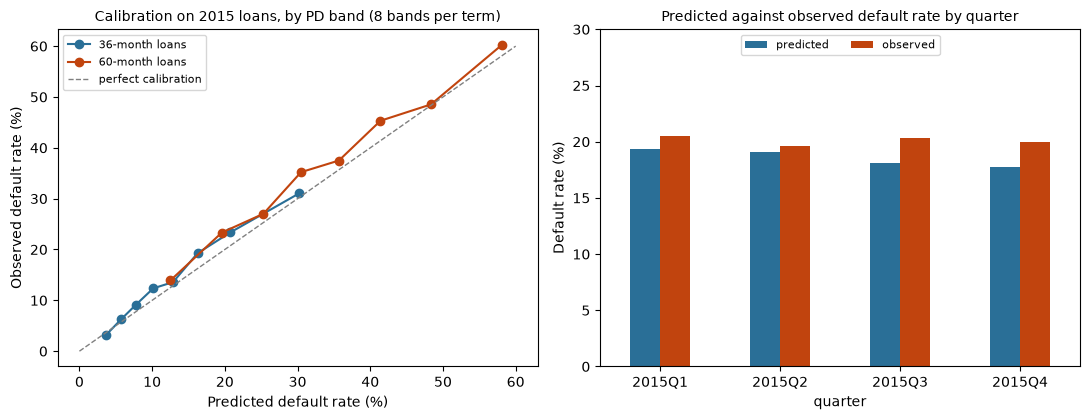

             all  36 months  60 months
slope      0.981      0.987      0.936
intercept  0.095      0.097      0.080

mean predicted PD 18.5% against observed 20.1%


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for term, color in [(36, "#2a6f97"), (60, "#c1440e")]:
    s = v15[v15.term == term]
    c = metrics.calibration_table(s.defaulted, s[SEL], bins=8)
    ax[0].plot(c.mean_pd * 100, c.default_rate * 100, "o-", color=color, label=f"{term}-month loans")
ax[0].plot([0, 60], [0, 60], color="grey", ls="--", lw=1, label="perfect calibration")
ax[0].set_xlabel("Predicted default rate (%)"); ax[0].set_ylabel("Observed default rate (%)"); ax[0].legend(fontsize=8)
ax[0].set_title("Calibration on 2015 loans, by PD band (8 bands per term)", fontsize=10)
q = v15.groupby("quarter").agg(predicted=(SEL, "mean"), observed=("defaulted", "mean")) * 100
q.plot.bar(ax=ax[1], color=["#2a6f97", "#c1440e"], rot=0); ax[1].set_ylabel("Default rate (%)"); ax[1].set_ylim(0, 30)
ax[1].set_title("Predicted against observed default rate by quarter", fontsize=10); ax[1].legend(loc="upper center", ncol=2, fontsize=8)
fig.tight_layout(); plt.show()

slopes = {k: metrics.calibration_slope_intercept(s.defaulted, s[SEL]) for k, s in [("all", v15), ("36 months", v15[v15.term == 36]), ("60 months", v15[v15.term == 60])]}
print(pd.DataFrame(slopes, index=["slope", "intercept"]).round(3).to_string())
print(f"\nmean predicted PD {v15[SEL].mean():.1%} against observed {v15.defaulted.mean():.1%}")

**Reading it.** The points sit close to the diagonal for both terms, and the slopes are near 1 (0.99 for 36-month, 0.94 for 60-month loans): high PDs are about as high as they should be and low PDs as low. The one consistent gap is the **level**: the model predicts 18.5% against 20.1% observed, and the positive intercept says the same. Default rose from 18.0% in 2014 to 20.1% in 2015, partly because the 60-month loans of 2015 are the early finishers. The gap also **widens through the year** (about 1 point in Q1 and 0.5 in Q2, about 2 points in Q3 and Q4): an early sign of drift, the kind of signal monitoring should catch. The ranking is unaffected; for pricing, the fix is to recalibrate on the latest complete vintage before go-live, and the drift monitoring in notebook 10 would flag a larger shift.

## 5. The decision policy: thresholds from the profit assumptions

For a loan of amount `A` with default probability `PD`, the expected profit is

`A x (0.10 x (1 - PD) - 0.70 x PD)`

It is zero when `0.10 x (1 - PD) = 0.70 x PD`, that is **PD = 0.10 / 0.80 = 12.5%**. Above that, a loan loses money on average, so 12.5% is the **auto-decline** line.

The **auto-approve** line is ours, not the brief's: a loan is approved without a human only if its expected margin is at least 5 cents per dollar (`min_approval_margin` in the config), which leaves room for error in the PD. That gives `(0.10 - 0.05) / 0.80` = **6.25%**. Loans in between go to **manual review**: on average they still earn a little, but not enough to fund unseen.

In [6]:
th = policy.thresholds(cfg)
print("thresholds:", th, f"| break-even PD: {policy.breakeven_pd(cfg):.4f}")
for p in [0.03, 0.0625, 0.10, 0.125, 0.20]:
    print(f"  PD {p:>6.2%}: expected margin per dollar {float(policy.margin_per_dollar(p, cfg)):+.4f} -> {policy.decide([p], th)[0]}")

thresholds: {'approve_below': 0.0625, 'decline_at_or_above': 0.125} | break-even PD: 0.1250
  PD  3.00%: expected margin per dollar +0.0760 -> approve
  PD  6.25%: expected margin per dollar +0.0500 -> review
  PD 10.00%: expected margin per dollar +0.0200 -> review
  PD 12.50%: expected margin per dollar +0.0000 -> decline
  PD 20.00%: expected margin per dollar -0.0600 -> decline


The break-even line follows from the assumptions alone. As a check, the profit-maximising decline threshold was searched on **2015 H1** only (the first half), funding every loan below each candidate line and adding up what actually happened:

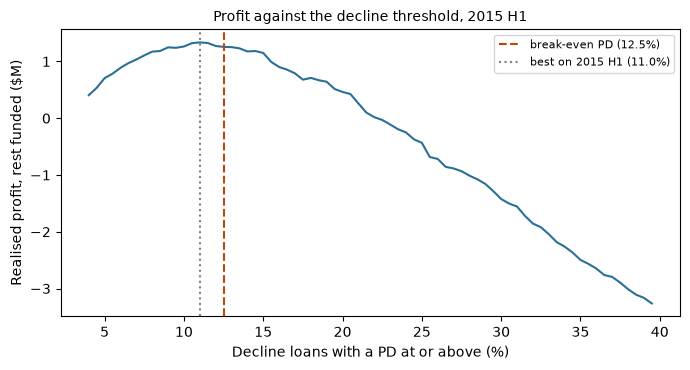

best threshold on H1: 0.110 (profit $1.34M); at break-even 0.125: $1.26M = 94% of the best


In [7]:
h1 = split(v15, cfg["policy_window"]["start"], cfg["policy_window"]["end"]).assign(pd=lambda t: t[SEL])
h2 = split(v15, cfg["report_window"]["start"], cfg["report_window"]["end"]).assign(pd=lambda t: t[SEL])
curve = policy.best_decline_threshold(h1, cfg)
best = curve.loc[curve.profit.idxmax()]
at_be = curve.loc[(curve.threshold - th["decline_at_or_above"]).abs().idxmin()]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve.threshold * 100, curve.profit / 1e6, color="#2a6f97")
ax.axvline(th["decline_at_or_above"] * 100, color="#c1440e", ls="--", label="break-even PD (12.5%)")
ax.axvline(best.threshold * 100, color="grey", ls=":", label=f"best on 2015 H1 ({best.threshold:.1%})")
ax.set_xlabel("Decline loans with a PD at or above (%)"); ax.set_ylabel("Realised profit, rest funded ($M)"); ax.legend(fontsize=8)
ax.set_title("Profit against the decline threshold, 2015 H1", fontsize=10); fig.tight_layout(); plt.show()
print(f"best threshold on H1: {best.threshold:.3f} (profit ${best.profit / 1e6:.2f}M); at break-even 0.125: ${at_be.profit / 1e6:.2f}M = {at_be.profit / best.profit:.0%} of the best")

**Reading it.** The empirical best on H1 is a little stricter (11%) than break-even, because the model under-predicts slightly (section 4); break-even still earns most of that optimum. We keep **12.5%**: it follows from the stated assumptions, not from one half-year of data, and it moves automatically if the assumptions change. The results below are reported on **2015 H2**, which played no part in this check.

### Approval and default rates under the policy (2015 H2)

In [8]:
bands = policy.band_table(h2, th, cfg)
print(bands[["decision", "loans", "share_of_loans", "default_rate", "mean_pd", "profit_if_funded", "profit_per_dollar"]].round(4).to_string(index=False))
print(f"\nfunding approve + review: {bands.loans.iloc[:2].sum() / bands.loans.sum():.1%} of loans, default rate {(bands.default_rate * bands.loans).iloc[:2].sum() / bands.loans.iloc[:2].sum():.1%}")

decision  loans  share_of_loans  default_rate  mean_pd  profit_if_funded  profit_per_dollar
 approve   1569          0.1760        0.0440   0.0442         1383065.0             0.0619
  review   2394          0.2685        0.1128   0.0927          169470.0             0.0055
 decline   4952          0.5555        0.2938   0.2635       -11582260.0            -0.1518

funding approve + review: 44.5% of loans, default rate 8.6%


**Reading it.**
- **Auto-approve: 17.6% of applicants, with a 4.4% default rate** (predicted 4.4%), earning about 6 cents per dollar lent.
- **Manual review: 27%**, default rate 11%; on average just above break-even, so the reviewer's judgement decides.
- **Auto-decline: 56%**, default rate 29%; funding them would have lost about 15 cents per dollar.

A decline rate of over half looks high, but it follows from the brief's economics: with a 7-to-1 ratio of loss to margin, any loan with more than a 1-in-8 chance of default loses money, and the average applicant here defaults 1 time in 5. On these assumptions the platform's historical book, funded in full, lost money (next section).

## 6. The policy driven by our model against the same policy driven by grade alone

In [9]:
cmp = pd.read_csv(TAB / "policy_model_vs_grade_2015H2.csv").set_index("policy_driven_by")
rates = cmp[["approval_rate", "review_rate", "decline_rate", "default_rate_of_approved"]].T.map("{:.1%}".format)
money = (cmp[["profit_if_only_approved_funded", "profit_if_approve_and_review_funded", "profit_fund_everyone"]].T / 1e6).map("${:+.2f}M".format)
print(pd.concat([rates, money]).to_string())
diff = pd.read_csv(TAB / "profit_difference_model_vs_grade_2015H2.csv").iloc[0]
print(f"\nprofit, model minus grade (approve + review funded): ${diff.profit_difference_model_minus_grade / 1e6:+.2f}M, 95% interval ${diff.ci_low / 1e6:+.2f}M to ${diff.ci_high / 1e6:+.2f}M "
      f"({int(diff.loans_funded_by_only_one_policy):,} loans funded by only one of the two)")

policy_driven_by                        model grade alone
approval_rate                           17.6%       18.6%
review_rate                             26.9%       16.4%
decline_rate                            55.5%       65.0%
default_rate_of_approved                 4.4%        5.1%
profit_if_only_approved_funded        $+1.38M     $+1.38M
profit_if_approve_and_review_funded   $+1.55M     $+1.69M
profit_fund_everyone                 $-10.03M    $-10.03M

profit, model minus grade (approve + review funded): $-0.14M, 95% interval $-0.43M to $+0.15M (1,189 loans funded by only one of the two)


**Reading it.** With the same thresholds, the two policies approve a similar share with a lower default rate for the model (4.4% against 5.1%), but the grade-driven policy funds fewer loans in total (35% against 44%) and ends up about $0.14M ahead; the interval runs from -$0.43M to +$0.15M, so **neither is shown to be better at fixed thresholds**. The two scores spread applicants differently around 12.5%, so this comparison mixes ranking with where each score happens to put the line.

The fair test of ranking is to fund the **same number of loans** under each score, the safest ones first, and compare what they earn:

In [10]:
for name, f in [("2015 H2", "profit_at_equal_volume_2015H2.csv"), ("all of 2015", "profit_at_equal_volume_2015_all.csv")]:
    eq = pd.read_csv(TAB / f)
    eq["share_of_loans_funded"] = eq.share_of_loans_funded.map("{:.1%}".format) + np.where(eq.is_policy_volume, " (policy volume)", "")
    print(f"{name}:")
    print((eq.set_index("share_of_loans_funded")[["profit_model", "profit_grade", "difference", "ci_low", "ci_high"]] / 1e6).round(2).to_string(), "\n")

2015 H2:
                       profit_model  profit_grade  difference  ci_low  ci_high
share_of_loans_funded                                                         
20.0%                          1.49          1.44        0.05   -0.16     0.22
30.0%                          1.79          1.63        0.16   -0.02     0.37
35.0%                          1.84          1.69        0.15   -0.08     0.43
40.0%                          1.69          1.55        0.13   -0.13     0.40
44.5% (policy volume)          1.55          1.43        0.12   -0.13     0.43
45.0%                          1.55          1.42        0.13   -0.16     0.42
50.0%                          1.53          1.07        0.46    0.12     0.77 

all of 2015:
                       profit_model  profit_grade  difference  ci_low  ci_high
share_of_loans_funded                                                         
20.0%                          2.48          2.54       -0.05   -0.34     0.21
30.0%                       

**Reading it.** At the volume the policy funds (44.5% of loans), the model's safest loans earn **$0.12M more** than the grade's on 2015 H2 (interval -$0.13M to +$0.43M, not conclusive on half a year) and **$0.52M more on all of 2015** (interval +$0.12M to +$0.92M, clear of zero). On the full year the gap grows as more loans are funded, because the further down the list, the more the ranking matters. So the AUC gain does turn into money, measured on a full year.

## 7. Outcomes by region and income band
Neither region nor income band is a model input (location is excluded, notebook 06; income enters only through the treated fields). They are monitored to check whether the policy treats groups very differently and whether it is calibrated for each. Region groups the states into the four US Census regions.

In [11]:
seg = pd.read_csv(TAB / "outcomes_by_region_and_income.csv")
seg["observed_95%"] = seg.ci_low.map("{:.1%}".format) + " to " + seg.ci_high.map("{:.1%}".format)
cols = ["segment", "level", "loans", "approval_rate", "review_rate", "decline_rate", "observed_default_rate", "observed_95%", "mean_predicted_pd", "default_rate_of_approved"]
print(seg[cols].round(3).to_string(index=False))

    segment     level  loans  approval_rate  review_rate  decline_rate  observed_default_rate   observed_95%  mean_predicted_pd  default_rate_of_approved
     region   Midwest   1588          0.172        0.271         0.557                  0.212 19.3% to 23.3%              0.186                     0.040
     region Northeast   1844          0.186        0.255         0.559                  0.206 18.8% to 22.5%              0.178                     0.041
     region     South   3272          0.164        0.270         0.566                  0.202 18.8% to 21.6%              0.181                     0.056
     region      West   2211          0.188        0.275         0.537                  0.189 17.3% to 20.6%              0.172                     0.034
income_band    40-60k   2416          0.123        0.288         0.589                  0.216 20.1% to 23.3%              0.190                     0.044
income_band    60-90k   2588          0.190        0.265         0.545      

**Reading it.**
- **Regions are treated alike**: approval rates 16% to 19%, decline rates 54% to 57%, and every region's predicted PD sits 1.7 to 2.8 points below its observed rate, the same overall under-prediction seen in section 4. No region stands out, which is what excluding location should give.
- **Income bands are treated very differently**, and that is expected: approval rises from 6% for incomes under $40k to 30% for $90k and above, because observed default falls as income rises (22.5% to 17.4%). The model's predicted PD is 1 to 3 points below the observed rate in every band, close to its overall gap, so the difference reflects risk, not a bias of the model against one group. It is still the kind of gap a credit team should look at with a fairness lens: income can correlate with protected characteristics, and the data has none to test directly.
- Default among approved loans stays between 3% and 6% in every group, well below break-even.

## Summary: what the brief asked, and where it is answered

| Brief item | Answered in |
|---|---|
| ROC-AUC, Gini, KS on the 2015 validation loans | section 1 |
| Comparison against grade alone | sections 1 and 2 (paired bootstrap), section 6 (in money) |
| Calibration plot | section 4 |
| Performance by quarter | section 3 |
| Auto-approve and auto-decline thresholds from the 70% loss / 10% margin assumptions | section 5 |
| Resulting approval and default rates | section 5 (bands on 2015 H2) |
| Outcomes across regions and income bands | section 7 |